In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

sns.set_theme(style="whitegrid")

# Load dataset (update path if running locally in Jupyter)
df = pd.read_csv(r"C:\Users\sanja\Downloads\archive (6)\WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Initial Shape:", df.shape)
print(df.head())

Initial Shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingM

In [7]:
# 1. Drop unique customerID column (no predictive value)
df = df.drop(columns=["customerID"])

# 2. Fix TotalCharges: stored as string with blank spaces for new customers
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing Values after conversion:\n", df.isnull().sum()[df.isnull().sum() > 0])

# Fill missing TotalCharges (tenure == 0) with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# 3. Encode target variable: Yes = 1 (Churned), No = 0 (Stayed)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("\nDuplicate Rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Clean Dataset Shape:", df.shape)
print("\nChurn Distribution:\n", df["Churn"].value_counts())

Missing Values after conversion:
 TotalCharges    11
dtype: int64

Duplicate Rows: 22
Clean Dataset Shape: (7021, 20)

Churn Distribution:
 Churn
0    5164
1    1857
Name: count, dtype: int64


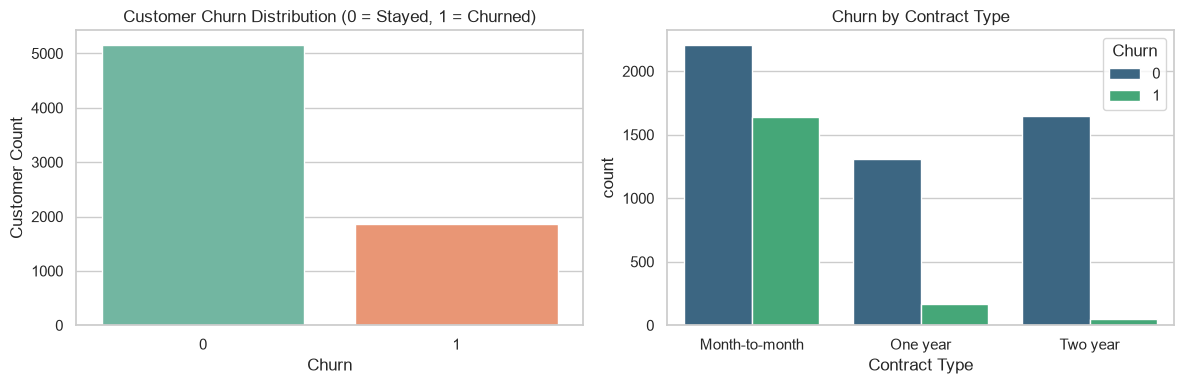

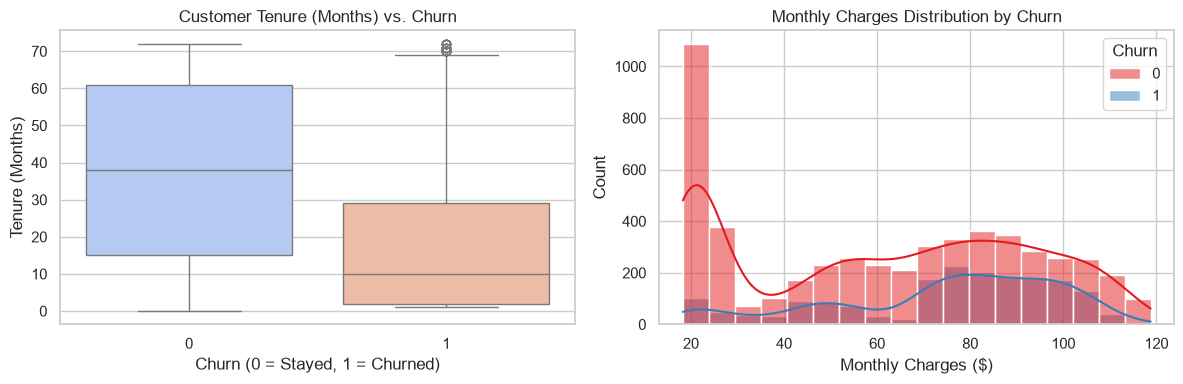

In [9]:
# Plot 1: Overall Churn Count & Churn by Contract Type
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="Churn", hue="Churn", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Customer Churn Distribution (0 = Stayed, 1 = Churned)")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Customer Count")

sns.countplot(data=df, x="Contract", hue="Churn", palette="viridis", ax=axes[1])
axes[1].set_title("Churn by Contract Type")
axes[1].set_xlabel("Contract Type")

plt.tight_layout()
plt.show()

# Plot 2: Tenure & Monthly Charges vs. Churn
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="Churn", y="tenure", hue="Churn", palette="coolwarm", legend=False, ax=axes[0])
axes[0].set_title("Customer Tenure (Months) vs. Churn")
axes[0].set_xlabel("Churn (0 = Stayed, 1 = Churned)")
axes[0].set_ylabel("Tenure (Months)")

sns.histplot(data=df, x="MonthlyCharges", hue="Churn", kde=True, palette="Set1", ax=axes[1])
axes[1].set_title("Monthly Charges Distribution by Churn")
axes[1].set_xlabel("Monthly Charges ($)")

plt.tight_layout()
plt.show()

In [10]:
    # Convert categorical text columns into numeric dummy columns
df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.drop(columns="Churn")
y = df_encoded["Churn"]

# Stratified split preserves churn ratio in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scaling inside Pipeline prevents data leakage
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['SeniorCitizen','tenure','MonthlyCharges',..., 'PaymentMethod_Credit card (automatic)','PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


--- Model Evaluation (Threshold = 0.5) ---
Confusion Matrix: TN=933, FP=100, FN=176, TP=196
Accuracy  : 0.8036
Precision : 0.6622
Recall    : 0.5269
F1-Score  : 0.5868
ROC-AUC   : 0.8404

Classification Report:

              precision    recall  f1-score   support

      Stayed       0.84      0.90      0.87      1033
     Churned       0.66      0.53      0.59       372

    accuracy                           0.80      1405
   macro avg       0.75      0.72      0.73      1405
weighted avg       0.79      0.80      0.80      1405



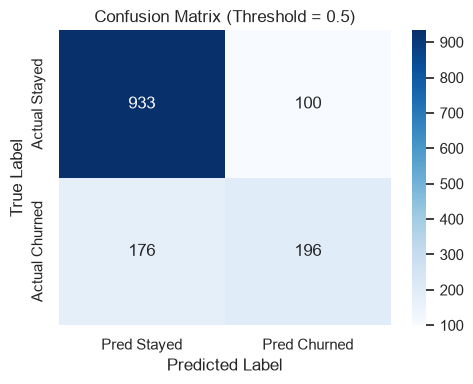


Top 5 Factors Increasing Churn:
                    feature  coefficient
               TotalCharges     0.672041
InternetService_Fiber optic     0.622899
          MultipleLines_Yes     0.187062
        StreamingMovies_Yes     0.186698
            StreamingTV_Yes     0.174692

Top 5 Factors Increasing Retention:
           feature  coefficient
OnlineSecurity_Yes    -0.125324
 Contract_One year    -0.272067
    MonthlyCharges    -0.535421
 Contract_Two year    -0.580891
            tenure    -1.410222

--- Decision Threshold Analysis ---
Threshold  Precision   Recall     F1-Score  
------------------------------------------
0.2        0.468       0.847      0.603     
0.3        0.535       0.742      0.622     
0.4        0.574       0.626      0.599     
0.5        0.662       0.527      0.587     
0.6        0.709       0.379      0.494     


In [11]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("--- Model Evaluation (Threshold = 0.5) ---")
print(f"Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob):.4f}")

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

# Confusion Matrix Heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Stayed", "Pred Churned"],
    yticklabels=["Actual Stayed", "Actual Churned"]
)
plt.title("Confusion Matrix (Threshold = 0.5)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Top 5 Features Driving Churn vs. Retention
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.named_steps["logreg"].coef_[0]
}).sort_values("coefficient", ascending=False)

print("\nTop 5 Factors Increasing Churn:")
print(coef_df.head(5).to_string(index=False))

print("\nTop 5 Factors Increasing Retention:")
print(coef_df.tail(5).to_string(index=False))

# Decision Threshold Tuning
print("\n--- Decision Threshold Analysis ---")
print(f"{'Threshold':<10} {'Precision':<11} {'Recall':<10} {'F1-Score':<10}")
print("-" * 42)
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pred_t = (y_prob >= t).astype(int)
    p = precision_score(y_test, pred_t, zero_division=0)
    r = recall_score(y_test, pred_t)
    f1 = f1_score(y_test, pred_t)
    print(f"{t:<10.1f} {p:<11.3f} {r:<10.3f} {f1:<10.3f}")